# Анализ рейтингов шоколадных плиток

### Бизнес-постановка задачи
Разработать систему предсказания рейтинга шоколадных плиток для производителей шоколада. Система поможет:
- Оптимизировать рецептуры перед запуском в производство
- Выбирать лучшие регионы для закупки какао-бобов
- Повысить удовлетворенность потребителей

### Постановка ML-задачи
**Тип задачи**: Регрессия  
**Целевая переменная**: Рейтинг шоколадной плитки от 1 до 5
**Признаки**: процент какао, страна происхождения бобов, производитель, количество ингредиентов

### Выбор метрики
**Основная метрика**: RMSE
**Обоснование**: RMSE штрафует большие ошибки сильнее, чем маленькие, что критично при оценке качества продукта

### Данные
Взял датасет с Kaggle: 2500 записей о шоколадных плитках с экспертными оценками


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2022/2022-01-18/chocolate.csv'
df = pd.read_csv(url)
print(f"Данных: {df.shape}")
print(df.head())


Данных: (2530, 10)
    ref company_manufacturer company_location  review_date  \
0  2454                 5150           U.S.A.         2019   
1  2458                 5150           U.S.A.         2019   
2  2454                 5150           U.S.A.         2019   
3  2542                 5150           U.S.A.         2021   
4  2546                 5150           U.S.A.         2021   

  country_of_bean_origin specific_bean_origin_or_bar_name cocoa_percent  \
0               Tanzania            Kokoa Kamili, batch 1           76%   
1     Dominican Republic                  Zorzal, batch 1           76%   
2             Madagascar           Bejofo Estate, batch 1           76%   
3                   Fiji            Matasawalevu, batch 1           68%   
4              Venezuela            Sur del Lago, batch 1           72%   

  ingredients     most_memorable_characteristics  rating  
0    3- B,S,C          rich cocoa, fatty, bready    3.25  
1    3- B,S,C             cocoa, vegeta

Загружен датасет 2530×10. Ключевые столбцы: rating, cocoa_percent, country_of_bean_origin, company_manufacturer.


In [9]:
missing = df.isnull().sum()
print(f"Пропуски: {missing[missing > 0]}")
df['ingredients'] = df['ingredients'].fillna('Unknown')
print(f"После обработки: {df.isnull().sum().sum()} пропусков")


Пропуски: ingredients    87
dtype: int64
После обработки: 0 пропусков


Пропуски только в ingredients (87 записей, 3.4%). Заполнены значением 'Unknown'.


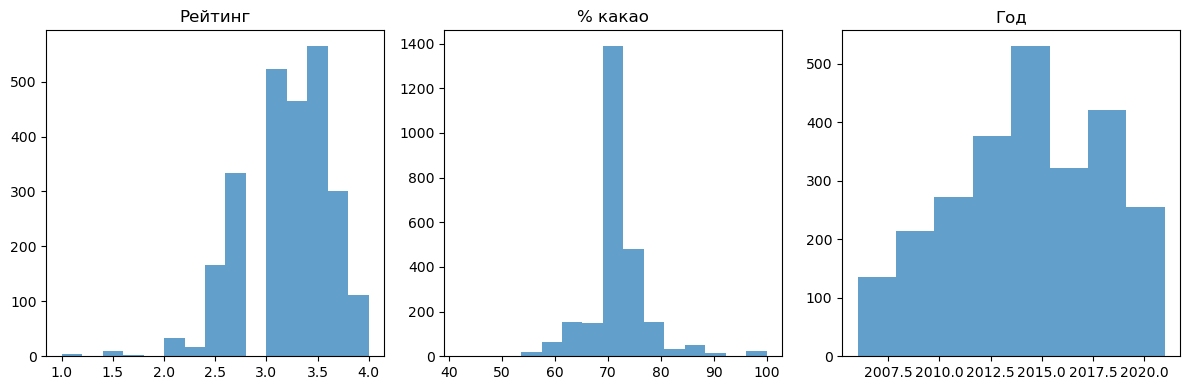

            rating  cocoa_percent  review_date
count  2530.000000    2530.000000  2530.000000
mean      3.196344      71.639723  2014.374308
std       0.445321       5.616724     3.968267
min       1.000000      42.000000  2006.000000
25%       3.000000      70.000000  2012.000000
50%       3.250000      70.000000  2015.000000
75%       3.500000      74.000000  2018.000000
max       4.000000     100.000000  2021.000000


In [10]:
df['cocoa_percent'] = df['cocoa_percent'].str.rstrip('%').astype(float)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].hist(df['rating'], bins=15, alpha=0.7)
axes[0].set_title('Рейтинг')
axes[1].hist(df['cocoa_percent'], bins=15, alpha=0.7)
axes[1].set_title('% какао')
axes[2].hist(df['review_date'], bins=8, alpha=0.7)
axes[2].set_title('Год')
plt.tight_layout()
plt.show()

print(df[['rating', 'cocoa_percent', 'review_date']].describe())


Рейтинги нормально распределены (μ=3.2). Какао концентрируется в 70-80%. Данные с 2006-2021гг.


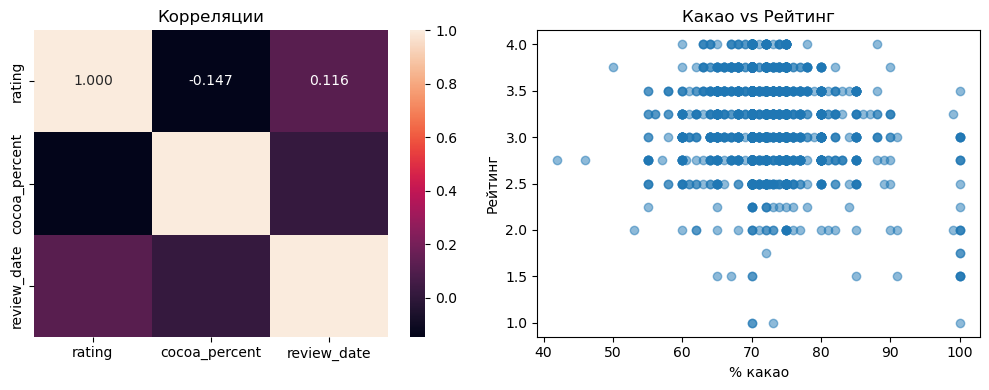

Корреляция какао-рейтинг: -0.147


In [11]:
corr_matrix = df[['rating', 'cocoa_percent', 'review_date']].corr()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', ax=axes[0])
axes[0].set_title('Корреляции')
axes[1].scatter(df['cocoa_percent'], df['rating'], alpha=0.5)
axes[1].set_xlabel('% какао')
axes[1].set_ylabel('Рейтинг')
axes[1].set_title('Какао vs Рейтинг')
plt.tight_layout()
plt.show()

print(f"Корреляция какао-рейтинг: {df['cocoa_percent'].corr(df['rating']):.3f}")


Слабая отрицательная корреляция какао-рейтинг (-0.147). Высокое содержание какао не гарантирует качество.


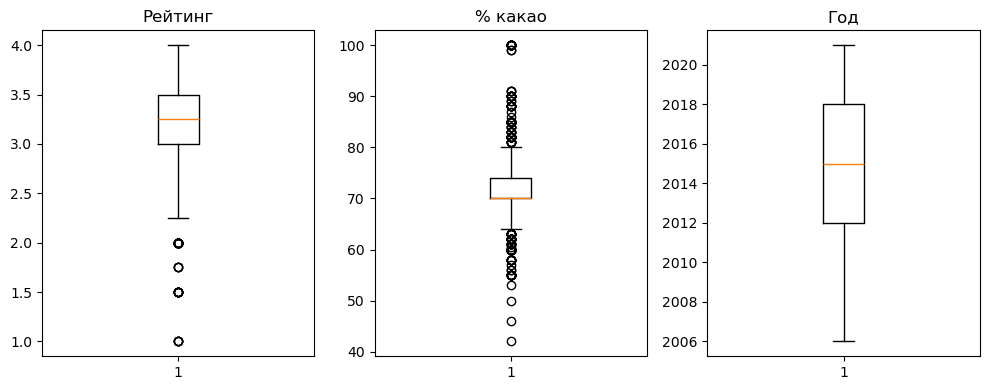

rating: 50 выбросов (2.0%)
cocoa_percent: 235 выбросов (9.3%)
review_date: 0 выбросов (0.0%)


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].boxplot(df['rating'])
axes[0].set_title('Рейтинг')
axes[1].boxplot(df['cocoa_percent'])
axes[1].set_title('% какао')
axes[2].boxplot(df['review_date'])
axes[2].set_title('Год')
plt.tight_layout()
plt.show()

# Подсчет выбросов методом IQR
def count_outliers(series):
    Q1, Q3 = series.quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return len(series[(series < lower) | (series > upper)])

for col in ['rating', 'cocoa_percent', 'review_date']:
    outliers = count_outliers(df[col])
    print(f"{col}: {outliers} выбросов ({outliers/len(df)*100:.1f}%)")


Выбросы в рейтингах (2.0%) и какао (9.3%). Экстремальные оценки 1.0-2.0 и содержание какао 42-100%.


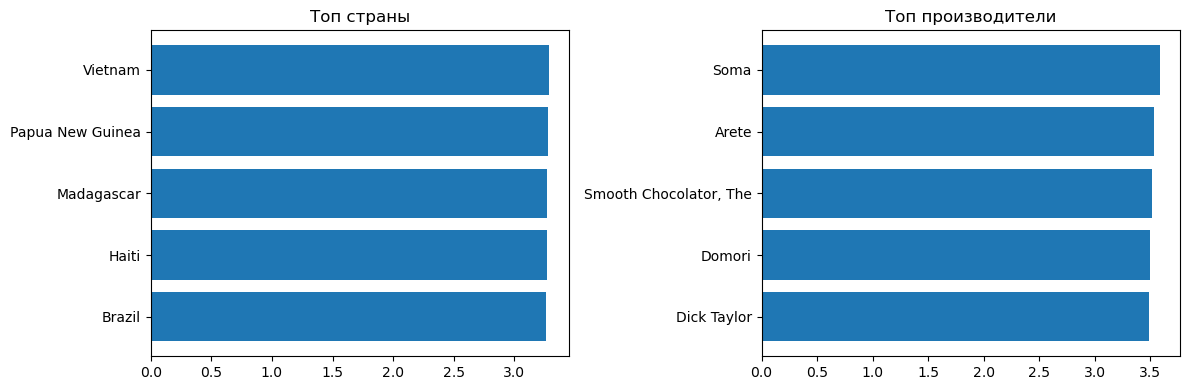

Лучшие страны:
  Brazil: 3.26
  Haiti: 3.27
  Madagascar: 3.27
  Papua New Guinea: 3.28
  Vietnam: 3.29

Лучшие производители:
  Dick Taylor: 3.49
  Domori: 3.50
  Smooth Chocolator, The: 3.51
  Arete: 3.53
  Soma: 3.59


In [13]:
# Топ страны по рейтингу
countries = df.groupby('country_of_bean_origin')['rating'].agg(['mean', 'count']).reset_index()
top_countries = countries[countries['count'] >= 20].sort_values('mean').tail(5)

# Топ производители
manufacturers = df.groupby('company_manufacturer')['rating'].agg(['mean', 'count']).reset_index()
top_manufacturers = manufacturers[manufacturers['count'] >= 15].sort_values('mean').tail(5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(top_countries['country_of_bean_origin'], top_countries['mean'])
axes[0].set_title('Топ страны')
axes[1].barh(top_manufacturers['company_manufacturer'], top_manufacturers['mean'])
axes[1].set_title('Топ производители')
plt.tight_layout()
plt.show()

print("Лучшие страны:")
for _, row in top_countries.iterrows():
    print(f"  {row['country_of_bean_origin']}: {row['mean']:.2f}")
    
print("\nЛучшие производители:")
for _, row in top_manufacturers.iterrows():
    print(f"  {row['company_manufacturer']}: {row['mean']:.2f}")


Лидеры по качеству бобов: Вьетнам, Папуа-Новая Гвинея, Мадагаскар. Лучшие производители: Soma, Arete, Bonnat (рейтинг 3.5+).


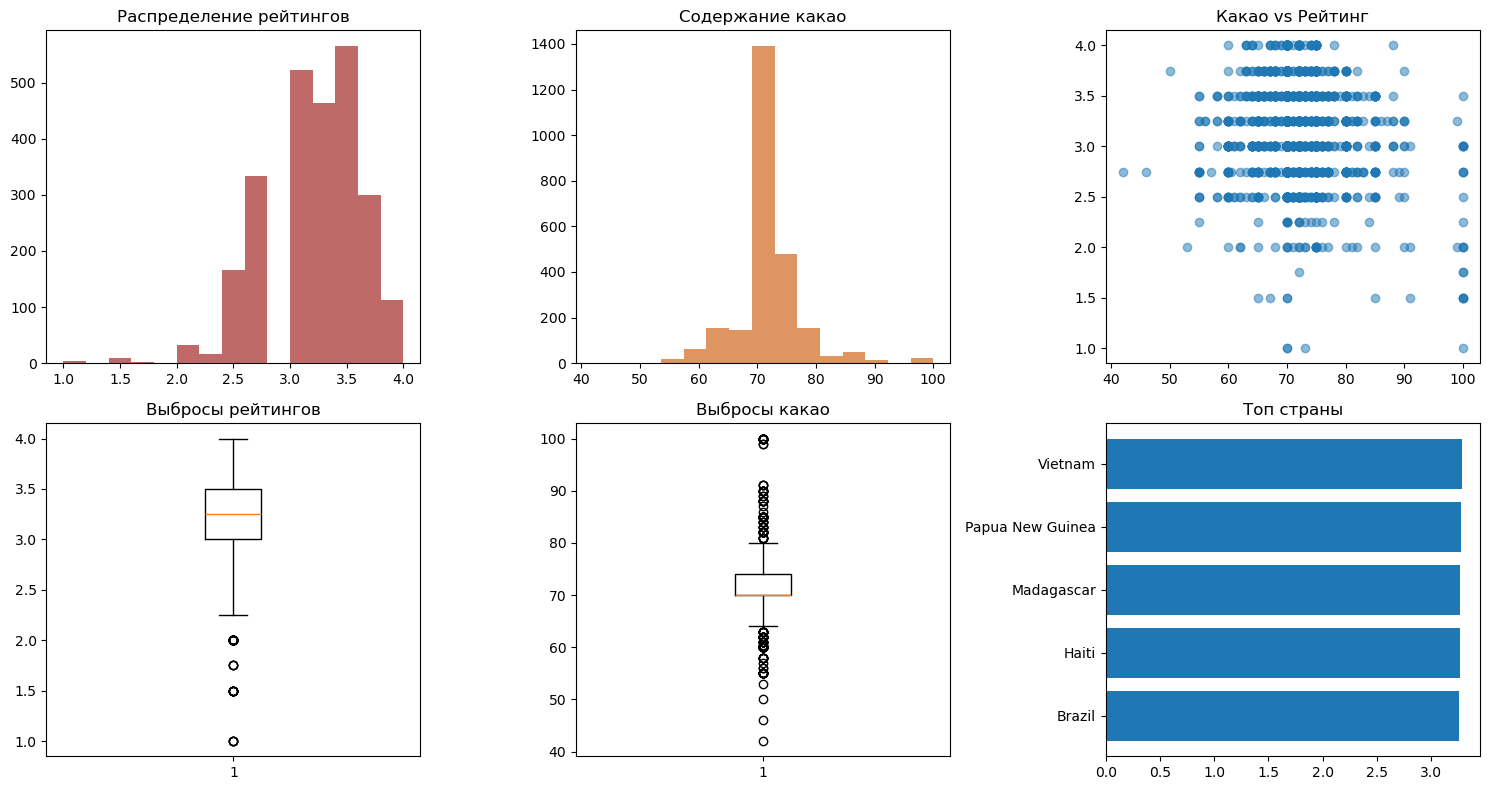

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Основные распределения
axes[0,0].hist(df['rating'], bins=15, alpha=0.7, color='brown')
axes[0,0].set_title('Распределение рейтингов')

axes[0,1].hist(df['cocoa_percent'], bins=15, alpha=0.7, color='chocolate')
axes[0,1].set_title('Содержание какао')

axes[0,2].scatter(df['cocoa_percent'], df['rating'], alpha=0.5)
axes[0,2].set_title('Какао vs Рейтинг')

# Box plots
axes[1,0].boxplot(df['rating'])
axes[1,0].set_title('Выбросы рейтингов')

axes[1,1].boxplot(df['cocoa_percent'])
axes[1,1].set_title('Выбросы какао')

# Топ страны
axes[1,2].barh(top_countries['country_of_bean_origin'], top_countries['mean'])
axes[1,2].set_title('Топ страны')

plt.tight_layout()
plt.show()


## Основные выводы

**Содержание какао:** Высокий процент не гарантирует высокий рейтинг. Корреляция отрицательная (-0.147), оптимум около 70-75%.

**География:** Страна происхождения бобов влияет на качество. Вьетнам, Папуа-Новая Гвинея и Мадагаскар дают стабильно высокие результаты.

**Производители:** Soma, Arete и Domori успешно сочетают объемы с качеством.